class distribution

In [6]:
# upload dataset
import pandas as pd
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Define the path to the dataset
dataset_path = '/content/drive/MyDrive/Colab/augmented.csv'

# Load the dataset
try:
    df = pd.read_csv(dataset_path)
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print(f"Error: The file '{dataset_path}' was not found. Please ensure it exists in your Google Drive.")
    df = None

if df is not None:
    # Display the first 5 rows of the DataFrame
    print("\nFirst 5 rows of the dataset:")
    display(df.head())
    # Display basic information about the DataFrame
    print("\nDataFrame Info:")
    df.info()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully.

First 5 rows of the dataset:


,user,gender,age,how_tall_in_meters,weight,body_mass_index,x1,y1,z1,x2,...,pitch2,yaw2,mag3,roll3,pitch3,yaw3,mag4,roll4,pitch4,yaw4
0,debora,Woman,46,1.62,75,28.6,-3,92,-63,-23,...,41.308515,141.952957,138.942434,131.496468,-2.062298,87.247515,233.918789,-144.981829,39.884957,-145.523912
1,debora,Woman,46,1.62,75,28.6,-3,94,-64,-21,...,39.521196,139.398705,138.246157,130.872408,5.812229,97.666804,232.469353,-144.350344,39.862300,-145.085476
2,debora,Woman,46,1.62,75,28.6,-1,97,-61,-12,...,25.641006,120.963757,138.148471,130.872408,5.399617,97.125016,233.137299,-144.162347,40.367439,-145.443194
3,debora,Woman,46,1.62,75,28.6,-2,96,-57,-15,...,29.603745,125.537678,137.499091,130.555894,5.425194,97.125016,232.770273,-144.044667,41.094312,-146.051457
4,debora,Woman,46,1.62,75,28.6,-1,96,-61,-13,...,27.474432,123.023868,137.499091,130.555894,5.425194,97.125016,233.824721,-143.972627,40.869343,-145.794542



DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165633 entries, 0 to 165632
Data columns (total 35 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   user                165633 non-null  object 
 1   gender              165633 non-null  object 
 2   age                 165633 non-null  int64  
 3   how_tall_in_meters  165633 non-null  float64
 4   weight              165633 non-null  int64  
 5   body_mass_index     165633 non-null  float64
 6   x1                  165633 non-null  int64  
 7   y1                  165633 non-null  int64  
 8   z1                  165633 non-null  int64  
 9   x2                  165633 non-null  int64  
 10  y2                  165633 non-null  int64  
 11  z2                  165633 non-null  int64  
 12  x3                  165633 non-null  int64  
 13  y3                  165633 non-null  int64  
 14  z3                  165633 non-null  int64  
 15  x4               

In [7]:
import re
import pandas as pd

# Check if 'df' is defined in the current scope and is a pandas DataFrame
if 'df' not in locals() or not isinstance(df, pd.DataFrame):
    print("Warning: DataFrame 'df' is not defined. Please ensure the cell loading the dataset (e.g., LsgEMxrwUZTj) has been executed successfully.")
    # Initialize present_cols as an empty list to prevent further errors
    present_cols = []
else:
    # Dynamically find columns that contain 'mag', 'roll', 'yaw', or 'pitch'
    present_cols = [col for col in df.columns if re.search(r'(mag|roll|yaw|pitch)\d+', col)]

print(f"Detected sensor columns for analysis: {present_cols}")

Detected sensor columns for analysis: ['mag1', 'roll1', 'pitch1', 'yaw1', 'mag2', 'roll2', 'pitch2', 'yaw2', 'mag3', 'roll3', 'pitch3', 'yaw3', 'mag4', 'roll4', 'pitch4', 'yaw4']


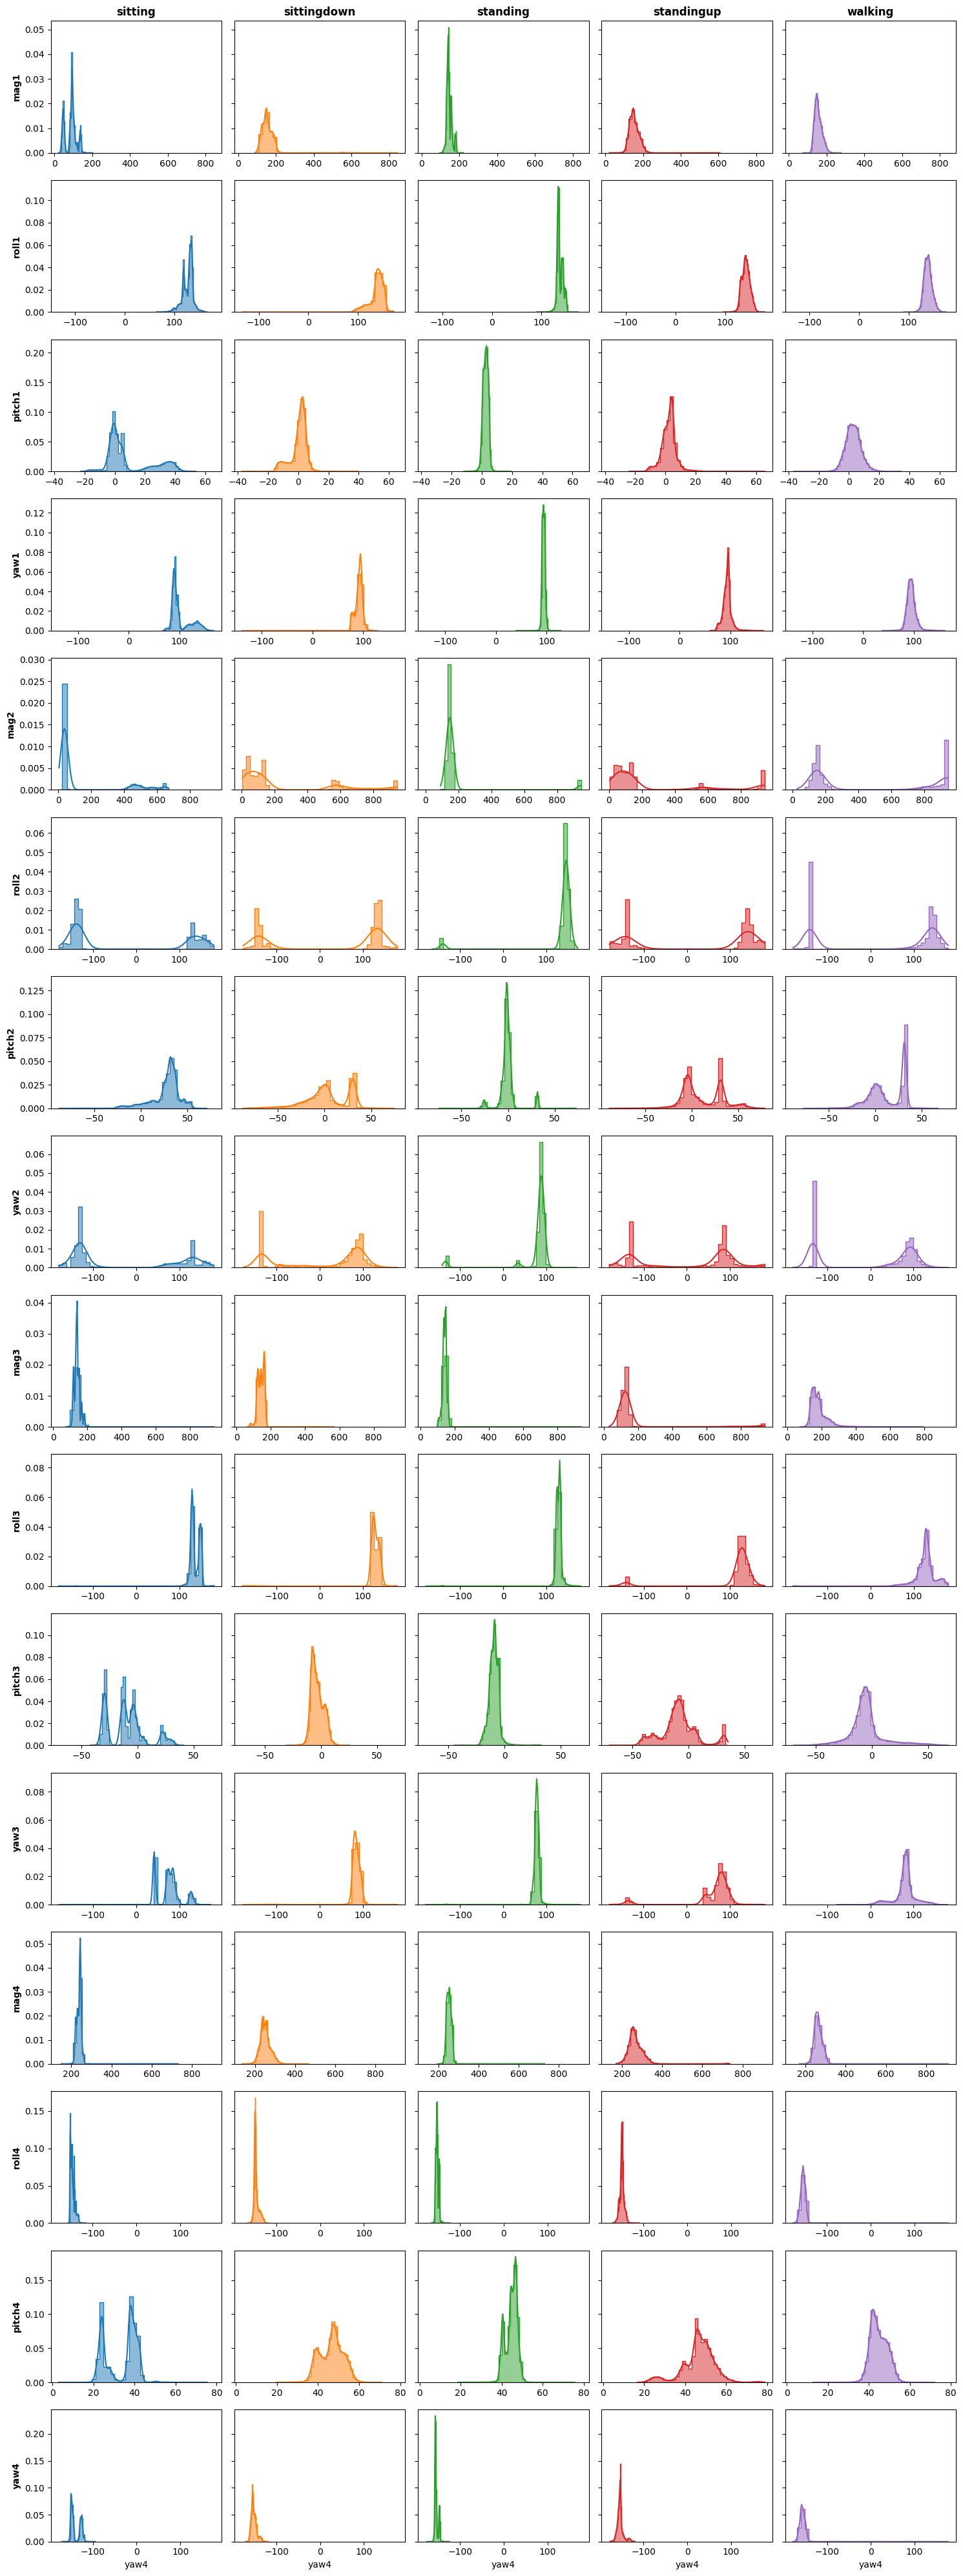

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

if 'class' in df.columns:
    classes = sorted(df['class'].unique())
    # The 'present_cols' variable should now contain 'mag', 'roll', 'yaw', 'pitch' features.
    # Ensure present_cols is defined and not empty before proceeding.
    if 'present_cols' not in locals() or not present_cols:
        print("Warning: 'present_cols' is not defined or is empty. Please ensure the cell defining sensor columns has been executed.")
    else:
        num_sensors = len(present_cols)
        num_classes = len(classes)

        if num_sensors == 0:
            print("Error: No sensor columns detected for plotting. Skipping histogram plot.")
        else:
            # AGGIUNTA: sharey='row' uniforma l'asse Y per ogni riga
            # AGGIUNTA: sharex='row' uniforma l'asse X per ogni riga (per vedere i range di accelerazione)
            fig, axes = plt.subplots(num_sensors, num_classes,
                                     figsize=(num_classes * 3, num_sensors * 2.5),
                                     sharex='row',
                                     sharey='row')

            if num_sensors == 1:
                axes = np.atleast_2d(axes)

            for i, sensor in enumerate(present_cols):
                # Calcoliamo i limiti globali per il sensore i-esimo per sicurezza (opzionale con sharex='row')
                sensor_min = df[sensor].min()
                sensor_max = df[sensor].max()

                for j, cls in enumerate(classes):
                    data_subset = df[df['class'] == cls][sensor].dropna()

                    # NOTA: stat='density' è fondamentale se le classi sono sbilanciate
                    # Se vuoi i conteggi puri, cambia in stat='count'
                    sns.histplot(data_subset, bins=40, kde=True, ax=axes[i, j],
                                 color=f'C{j}', stat='density', element="step")

                    # Etichette delle colonne (Attività)
                    if i == 0:
                        axes[i, j].set_title(f"{cls}", fontsize=12, fontweight='bold')

                    # Etichette delle righe (Sensore)
                    if j == 0:
                        axes[i, j].set_ylabel(sensor, fontsize=10, fontweight='bold')
                    else:
                        axes[i, j].set_ylabel("")

                    # Pulizia asse X per i grafici intermedi
                    if i < num_sensors - 1:
                        axes[i, j].set_xlabel("")

            plt.tight_layout()
            plt.show()
else:
    print("DataFrame does not contain a 'class' column. Skipping plot.")

/tmp/ipykernel_1270/1995232181.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='class', y=sensor, data=df, ax=axes[i], palette='Set2')
/tmp/ipykernel_1270/1995232181.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='class', y=sensor, data=df, ax=axes[i], palette='Set2')
/tmp/ipykernel_1270/1995232181.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='class', y=sensor, data=df, ax=axes[i], palette='Set2')
/tmp/ipykernel_1270/1995232181.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will b

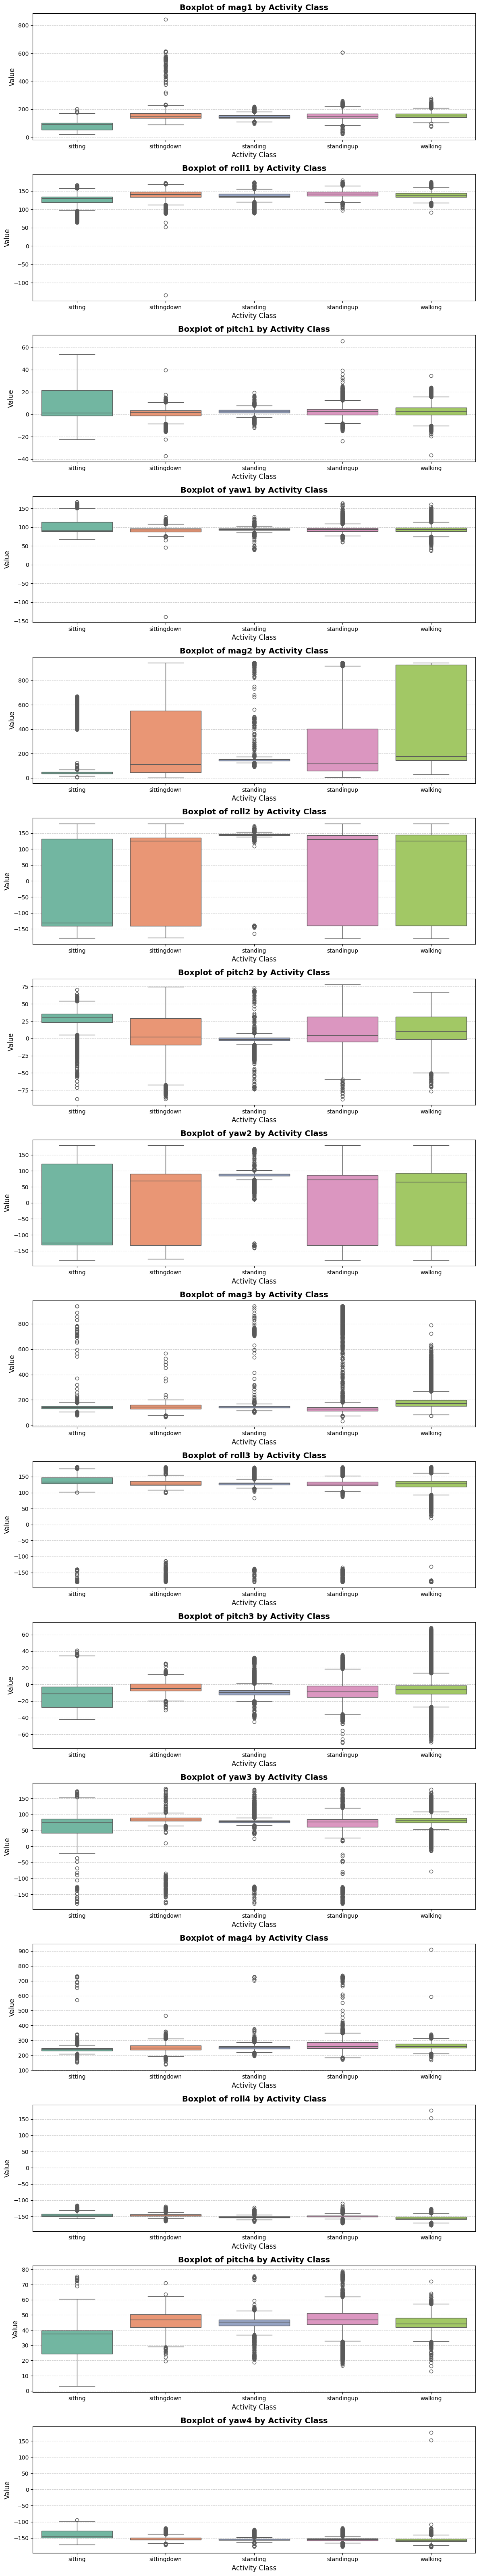

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'class' in df.columns:
    # Ensure present_cols is defined and not empty before proceeding.
    if 'present_cols' not in locals() or not present_cols:
        print("Warning: 'present_cols' is not defined or is empty. Please ensure the cell defining sensor columns has been executed.")
    else:
        num_sensors = len(present_cols)

        if num_sensors == 0:
            print("Error: No sensor columns detected for plotting. Skipping boxplot.")
        else:
            # We create one row per sensor.
            # All activity classes are shown on the X-axis for easy comparison.
            fig, axes = plt.subplots(num_sensors, 1, figsize=(12, num_sensors * 4))

            # Ensure axes is an array even if there is only one sensor
            if num_sensors == 1:
                axes = [axes]

            for i, sensor in enumerate(present_cols):
                # Create the boxplot
                sns.boxplot(x='class', y=sensor, data=df, ax=axes[i], palette='Set2')

                # Formatting and labeling
                axes[i].set_title(f'Boxplot of {sensor} by Activity Class', fontsize=14, fontweight='bold')
                axes[i].set_xlabel('Activity Class', fontsize=12)
                axes[i].set_ylabel('Value', fontsize=12)

                # Add a light grid for better readability of values
                axes[i].grid(axis='y', linestyle='--', alpha=0.6)

            plt.tight_layout()
            plt.show()
else:
    print("DataFrame does not contain a 'class' column. Skipping boxplot.")

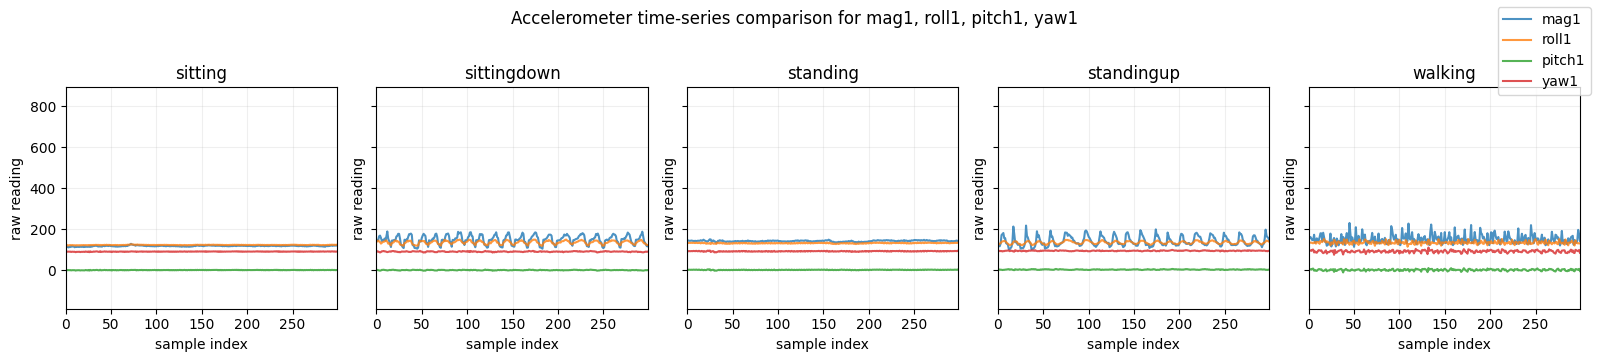

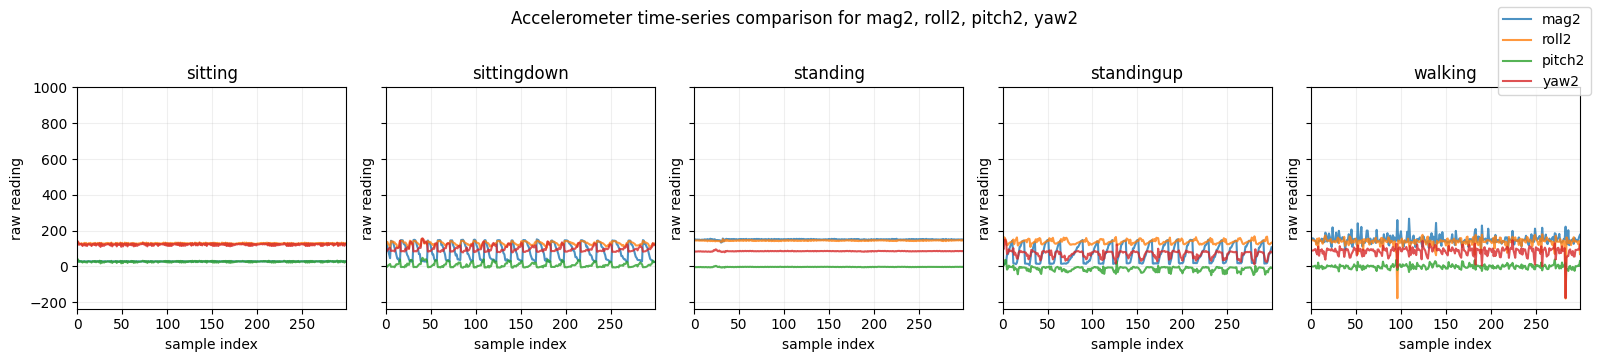

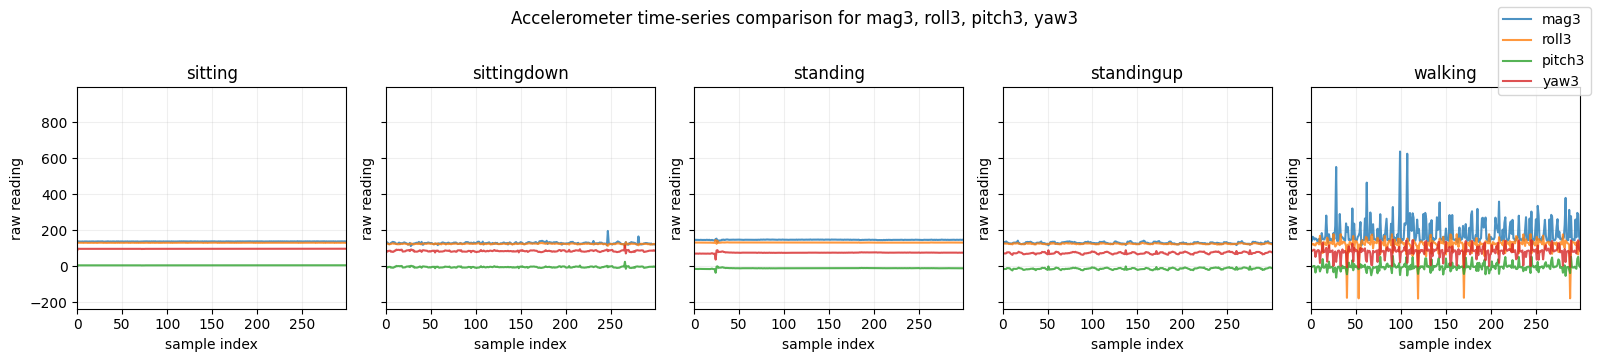

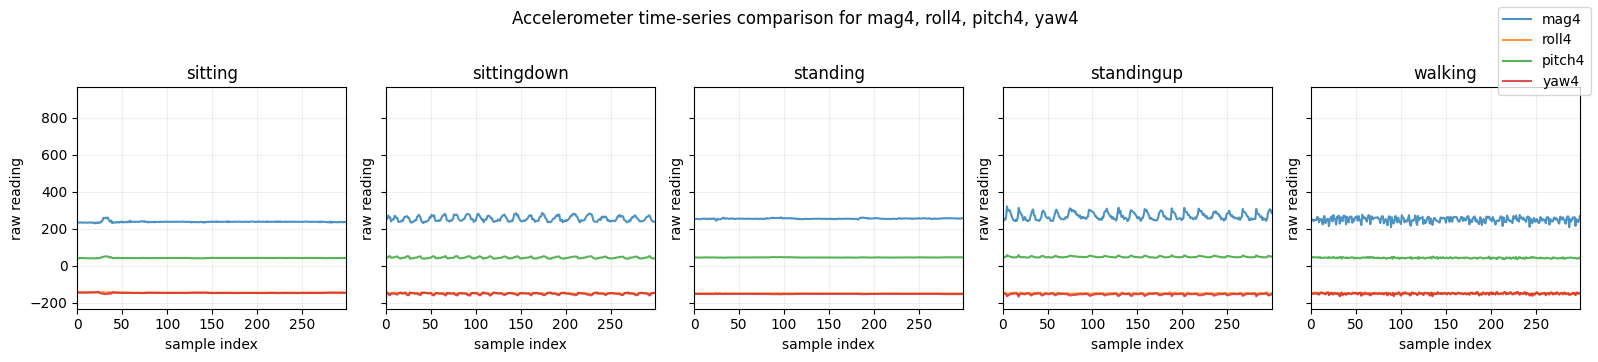

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np # Ensure numpy is imported for array operations

# Sensor-wise class comparison: one figure per accelerometer triple, with all classes as subplots
class_col = 'class' if 'class' in df.columns else None
if class_col is not None:
    # Ensure present_cols is defined and not empty before proceeding.
    if 'present_cols' not in locals() or not present_cols:
        print("Warning: 'present_cols' is not defined or is empty. Please ensure the cell defining sensor columns has been executed.")
    else:
        # Assuming 'class' column is categorical or can be treated as such
        # If it's not already categorical, convert it to handle 'cat.categories'
        if not hasattr(df[class_col].dtype, 'categories'):
            df[class_col] = df[class_col].astype('category')
        class_values = list(df[class_col].dropna().cat.categories)

        sensor_groups = [
            ('mag1, roll1, pitch1, yaw1', ['mag1', 'roll1', 'pitch1', 'yaw1']),
            ('mag2, roll2, pitch2, yaw2', ['mag2', 'roll2', 'pitch2', 'yaw2']),
            ('mag3, roll3, pitch3, yaw3', ['mag3', 'roll3', 'pitch3', 'yaw3']),
            ('mag4, roll4, pitch4, yaw4', ['mag4', 'roll4', 'pitch4', 'yaw4'])
        ]

        for sensor_name, sensor_axes in sensor_groups:
            # Only consider axes that are present in the dataframe (i.e., in present_cols)
            available_axes = [axis for axis in sensor_axes if axis in present_cols]
            if len(available_axes) == 0:
                print(f"Skipping plot for {sensor_name}: No relevant sensor axes found in 'present_cols'.")
                continue

            sensor_values = df[available_axes].to_numpy().ravel()
            sensor_values = sensor_values[~np.isnan(sensor_values)]
            if len(sensor_values) > 0:
                lower = float(np.min(sensor_values))
                upper = float(np.max(sensor_values))
                padding = 0.05 * (upper - lower if upper > lower else 1.0)
                y_limits = (lower - padding, upper + padding)
            else:
                y_limits = None

            n_classes = len(class_values)
            if n_classes == 0:
                print(f"Skipping plot for {sensor_name}: No activity classes found.")
                continue

            n_cols = min(n_classes, 5) # Limit columns to 5 for better readability
            n_rows = int(np.ceil(n_classes / n_cols))

            fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows), sharex=True, sharey=True)
            axes = np.array(axes).ravel()

            for ax, class_name in zip(axes, class_values):
                class_sample = df[df[class_col] == class_name].head(300)
                if len(class_sample) == 0:
                    ax.axis('off')
                    continue
                for axis in available_axes:
                    ax.plot(class_sample[axis].values, label=axis, alpha=0.8)
                ax.set_title(f'{class_name}')
                ax.set_xlabel('sample index')
                ax.set_ylabel('raw reading')
                ax.set_xlim(0, max(len(class_sample) - 1, 1))
                if y_limits is not None:
                    ax.set_ylim(*y_limits)
                ax.grid(True, alpha=0.2)

            for ax in axes[len(class_values):]:
                ax.axis('off')

            handles, labels = axes[0].get_legend_handles_labels() if len(class_values) > 0 else ([], [])
            if handles:
                fig.legend(handles, labels, loc='upper right')
            fig.suptitle(f'Accelerometer time-series comparison for {sensor_name}', y=1.02)
            plt.tight_layout()
            plt.show()
else:
    print("DataFrame does not contain a 'class' column. Skipping sensor-wise class comparison plot.")

Mean Absolute Value (MAV) per axis:


class,sitting,sittingdown,standing,standingup,walking
mag1,86.241622,155.732381,145.918994,152.978120,155.680686
roll1,126.941371,137.680851,136.970282,141.783352,138.848191
pitch1,10.858240,3.976752,2.650210,4.044287,4.524096
yaw1,101.305384,91.698329,93.869420,93.776041,94.707658
mag2,128.779112,245.779397,186.513301,260.487339,460.565357


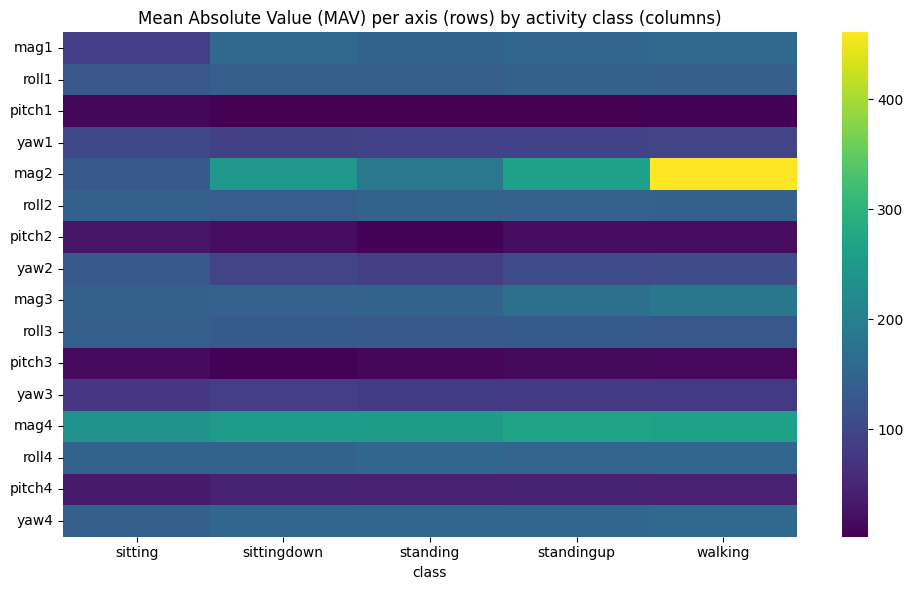

Variance per axis:


class,sitting,sittingdown,standing,standingup,walking
mag1,850.402056,1615.264439,197.648398,675.540328,375.027780
roll1,128.267316,215.389161,41.768602,69.227676,66.083221
pitch1,227.079169,27.055086,3.183026,22.437485,24.948393
yaw1,372.428937,52.943840,9.266518,69.575842,77.972204
mag2,37297.363519,85356.448637,29013.529984,96907.066217,137439.788893


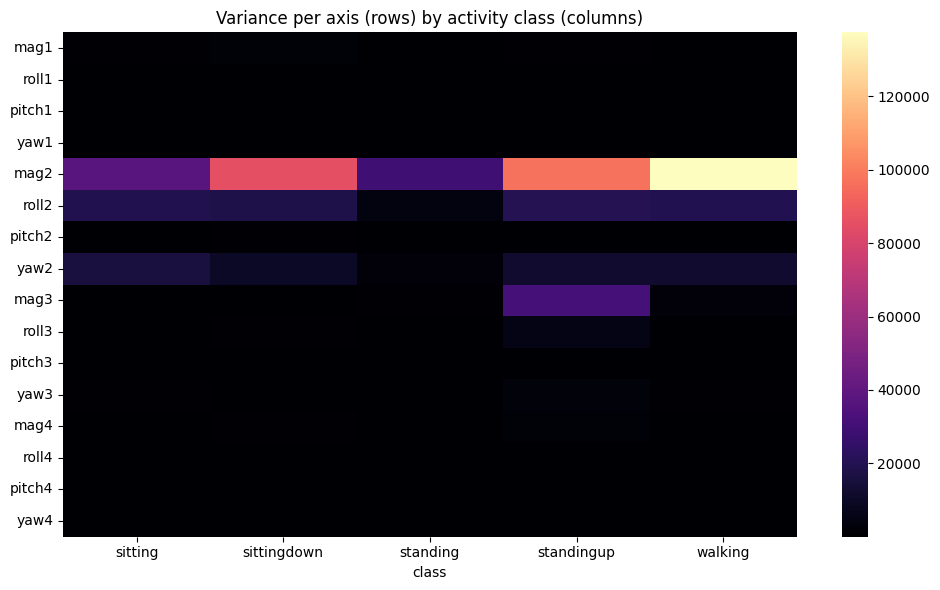

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Check if 'class' column exists before proceeding
if 'class' in df.columns:

    # 1. Mean Absolute Value (MAV) per axis grouped by activity class
    # Helps identify which sensors have the strongest average signal per activity
    mav = df.groupby('class', observed=False)[present_cols].apply(lambda x: x.abs().mean()).T

    print("Mean Absolute Value (MAV) per axis:")
    display(mav.head())

    plt.figure(figsize=(10, 6))
    sns.heatmap(mav, cmap='viridis')
    plt.title('Mean Absolute Value (MAV) per axis (rows) by activity class (columns)')
    plt.tight_layout()
    plt.show()

    # 2. Variance per axis grouped by activity class
    # Helps identify which sensors have the most fluctuations/turbulence per activity
    vav = df.groupby('class', observed=False)[present_cols].var().T

    print("Variance per axis:")
    display(vav.head())

    plt.figure(figsize=(10, 6))
    sns.heatmap(vav, cmap='magma')
    plt.title('Variance per axis (rows) by activity class (columns)')
    plt.tight_layout()
    plt.show()